# Heart Disease UCI — Exploratory Data Analysis

**Author:** Shashank Pandey (BITS ID: 2025AE05689)
**Course:** AIMLCZG523 — MLOps, Assignment 1

Goal of this notebook: understand the Cleveland Heart Disease dataset before
building any models — check data quality, look at distributions, and see
which features seem to actually separate the two classes. The final
preprocessing pipeline used for training lives in `src/features/build_features.py`
(this notebook is exploratory, not the production path — I don't want
leakage from "cleaning decisions" made by eyeballing plots).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 110

df = pd.read_csv("../data/raw/heart_disease.csv")
df.shape


(303, 14)

## 1. First look at the data

In [2]:
df.head(10)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0
5,56.0,1.0,2.0,120.0,236.0,0.0,0.0,178.0,0.0,0.8,1.0,0.0,3.0,0
6,62.0,0.0,4.0,140.0,268.0,0.0,2.0,160.0,0.0,3.6,3.0,2.0,3.0,1
7,57.0,0.0,4.0,120.0,354.0,0.0,0.0,163.0,1.0,0.6,1.0,0.0,3.0,0
8,63.0,1.0,4.0,130.0,254.0,0.0,2.0,147.0,0.0,1.4,2.0,1.0,7.0,1
9,53.0,1.0,4.0,140.0,203.0,1.0,2.0,155.0,1.0,3.1,3.0,0.0,7.0,1


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


Thirteen predictors + the binary `target` I derived in `download_data.py`
(original UCI label `num` goes from 0-4 severity; I collapsed 1-4 into
"disease present" since the assignment asks for a binary classifier).

Quick column reference since the raw UCI names are cryptic:

| column | meaning |
|---|---|
| age | age in years |
| sex | 1 = male, 0 = female |
| cp | chest pain type (1-4) |
| trestbps | resting blood pressure (mm Hg) |
| chol | serum cholesterol (mg/dl) |
| fbs | fasting blood sugar > 120 mg/dl (1 = true) |
| restecg | resting ECG results (0-2) |
| thalach | max heart rate achieved |
| exang | exercise induced angina (1 = yes) |
| oldpeak | ST depression induced by exercise |
| slope | slope of peak exercise ST segment |
| ca | number of major vessels colored by fluoroscopy (0-3) |
| thal | thalassemia (3 = normal, 6 = fixed defect, 7 = reversible defect) |


In [4]:
df.isna().sum().to_frame("missing_count")

,missing_count
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


Only `ca` (4 missing) and `thal` (2 missing) have gaps — 6 rows total out
of 303. That's small enough that median/mode imputation won't meaningfully
distort anything; I'm not going to drop rows over this.

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


## 2. Target balance

Checking this first because it decides whether I need `class_weight`,
stratified splits, or resampling later.

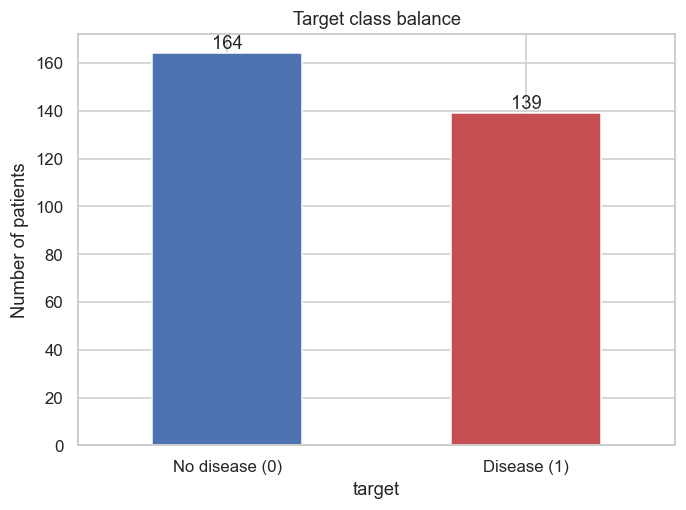

target
0    0.541
1    0.459
Name: proportion, dtype: float64


In [6]:
target_counts = df["target"].value_counts().sort_index()
ax = target_counts.plot(kind="bar", color=["#4C72B0", "#C44E52"])
ax.set_xticklabels(["No disease (0)", "Disease (1)"], rotation=0)
ax.set_ylabel("Number of patients")
ax.set_title("Target class balance")
for i, v in enumerate(target_counts):
    ax.text(i, v + 2, str(v), ha="center")
plt.tight_layout()
plt.savefig("../docs/figures/target_balance.png")
plt.show()

print(df["target"].value_counts(normalize=True).round(3))


54% / 46% split — close enough to balanced that I won't bother with
SMOTE or aggressive class weighting. Stratified train/test split is still
worth doing just to be safe with such a small dataset (303 rows).

## 3. Distributions of numeric features

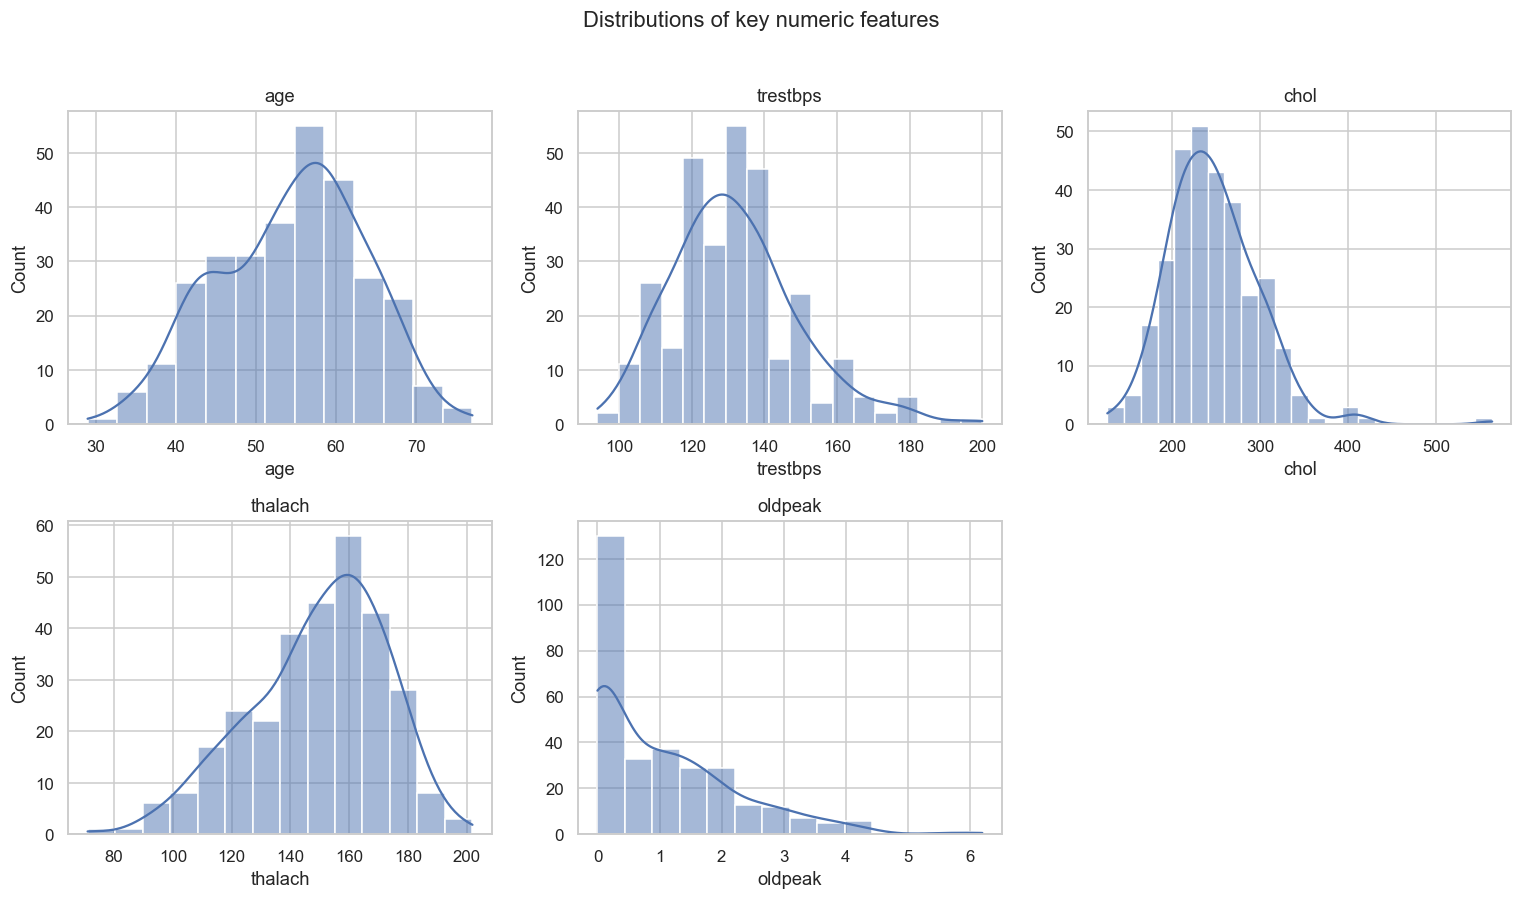

In [7]:
numeric_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()
for ax, col in zip(axes, numeric_cols):
    sns.histplot(df[col], kde=True, ax=ax, color="#4C72B0")
    ax.set_title(col)
axes[-1].axis("off")
plt.suptitle("Distributions of key numeric features", y=1.02)
plt.tight_layout()
plt.savefig("../docs/figures/numeric_histograms.png", bbox_inches="tight")
plt.show()


`chol` and `trestbps` are right-skewed with a handful of high outliers —
expected for medical measurements, not data errors, so I'll keep them and
let scaling handle the magnitude rather than clipping/removing anything.
`oldpeak` has a big spike at 0, which makes sense (most patients show no
ST depression at rest).

## 4. Numeric features vs. target

/var/folders/hc/s5z1cqk17b32rhvhcfd3rcx80000gp/T/ipykernel_41256/3650991711.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="target", y=col, ax=ax, palette=["#4C72B0", "#C44E52"])
/var/folders/hc/s5z1cqk17b32rhvhcfd3rcx80000gp/T/ipykernel_41256/3650991711.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["No disease", "Disease"])
/var/folders/hc/s5z1cqk17b32rhvhcfd3rcx80000gp/T/ipykernel_41256/3650991711.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="target", y=col, ax=ax, palette=["#4C72B0", "#C44E52"])
/var/folders/hc/s5z1cqk17b32rhvhcfd3rcx80000gp/T/i

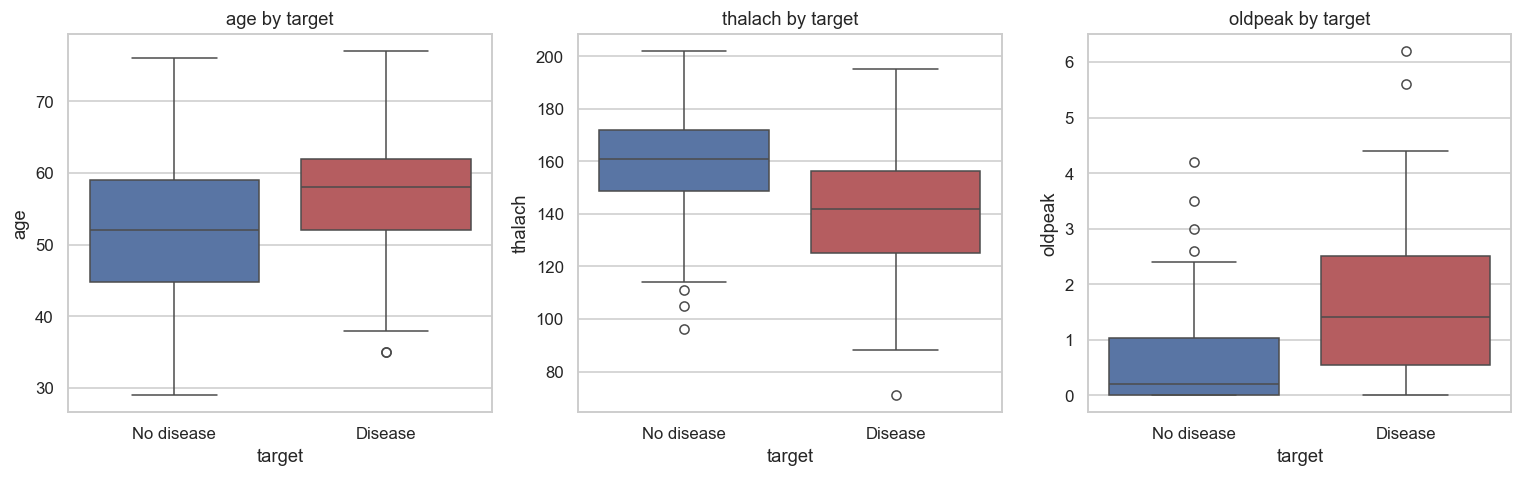

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, col in zip(axes, ["age", "thalach", "oldpeak"]):
    sns.boxplot(data=df, x="target", y=col, ax=ax, palette=["#4C72B0", "#C44E52"])
    ax.set_xticklabels(["No disease", "Disease"])
    ax.set_title(f"{col} by target")
plt.tight_layout()
plt.savefig("../docs/figures/numeric_vs_target.png")
plt.show()


`thalach` (max heart rate) is clearly lower in the disease group, and
`oldpeak` is clearly higher — both line up with the clinical intuition
(reduced exercise capacity, more ST depression under stress for diseased
hearts). These two look like they'll be useful predictors.

## 5. Categorical / discrete features vs. target

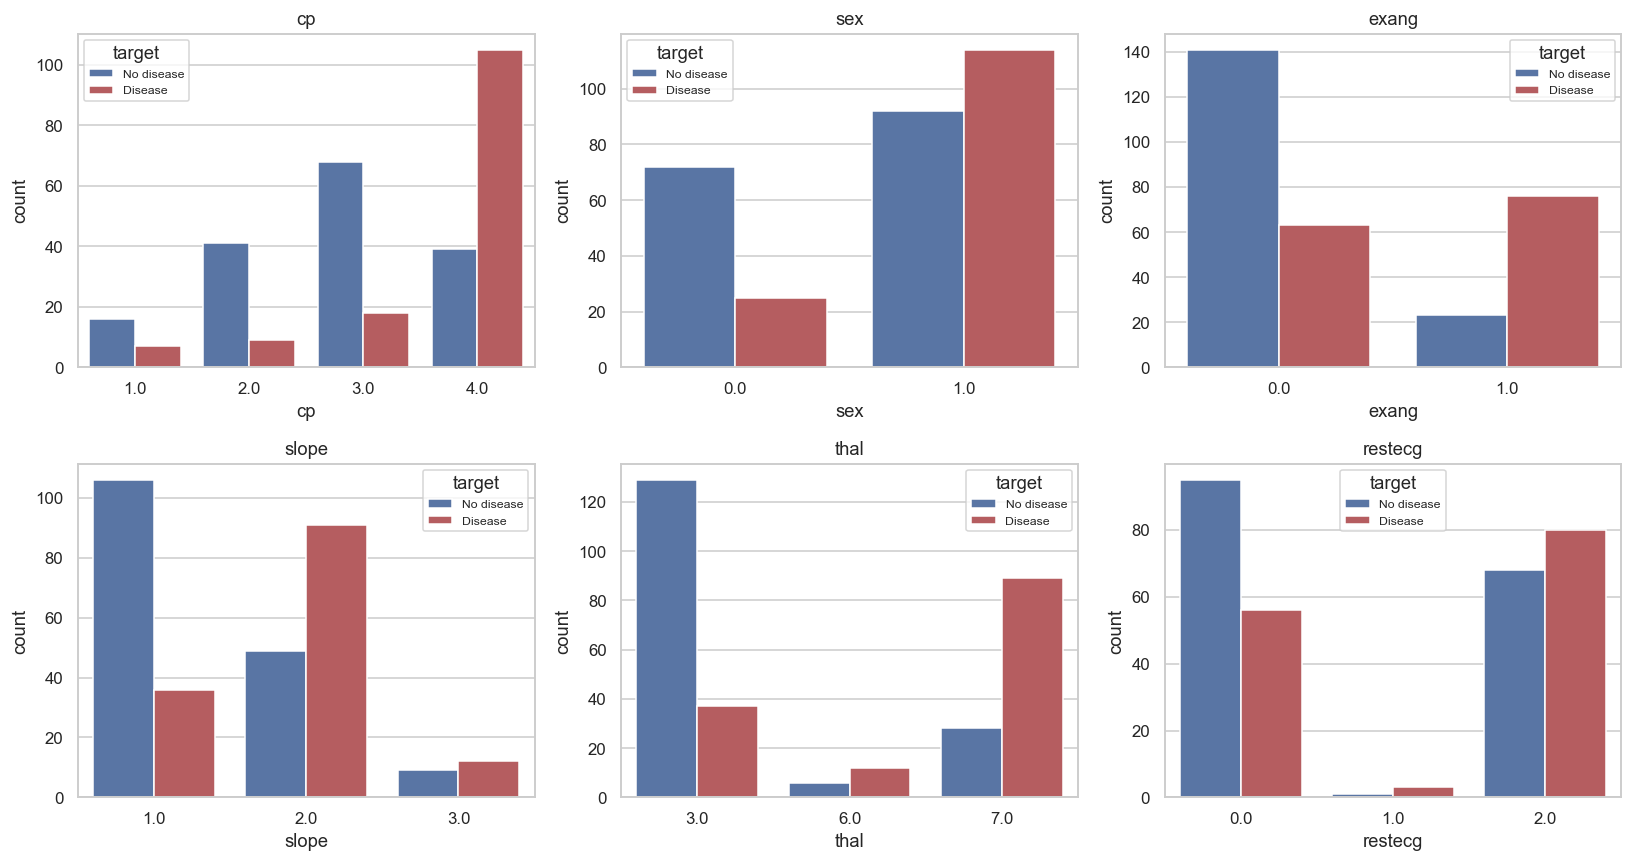

In [9]:
cat_cols = ["cp", "sex", "exang", "slope", "thal", "restecg"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
for ax, col in zip(axes, cat_cols):
    sns.countplot(data=df, x=col, hue="target", ax=ax, palette=["#4C72B0", "#C44E52"])
    ax.set_title(col)
    ax.legend(title="target", labels=["No disease", "Disease"], fontsize=8)
plt.tight_layout()
plt.savefig("../docs/figures/categorical_vs_target.png")
plt.show()


`cp` (chest pain type) and `thal` jump out immediately — certain
categories are almost entirely one class. `exang` (exercise-induced angina)
also separates the classes well: patients with `exang = 1` are disproportionately
in the disease group. These will likely end up as the top features by
importance once I train a tree-based model.

## 6. Correlation heatmap

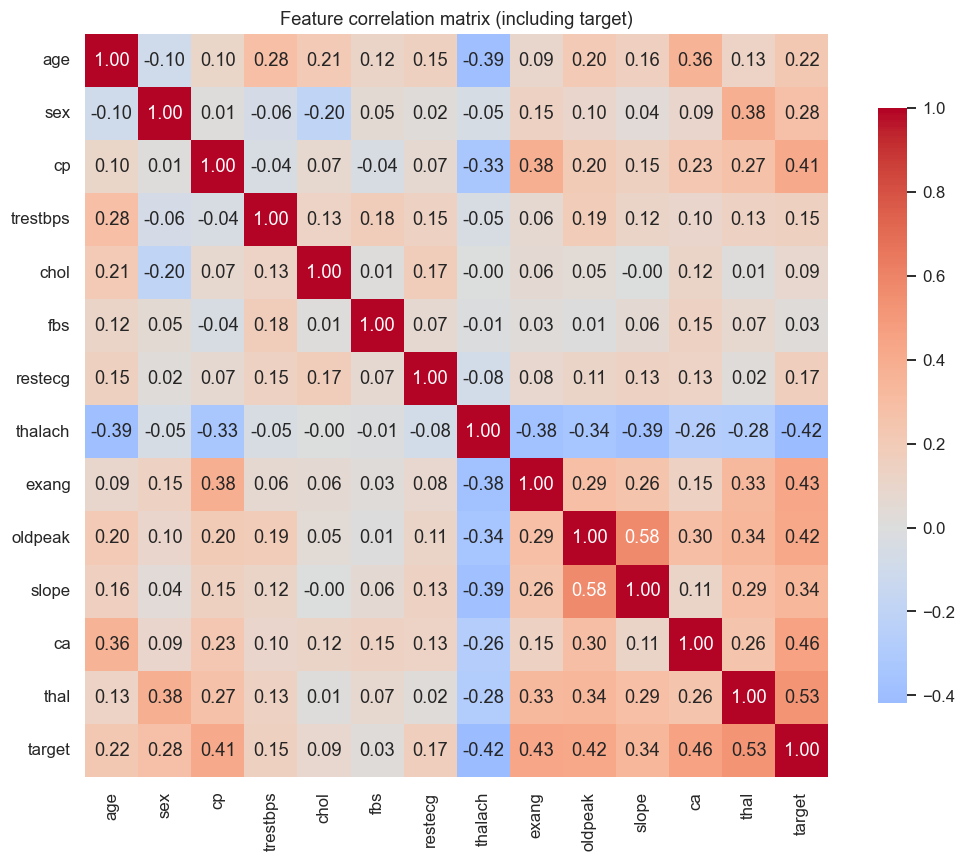

In [10]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True,
            cbar_kws={"shrink": 0.8})
plt.title("Feature correlation matrix (including target)")
plt.tight_layout()
plt.savefig("../docs/figures/correlation_heatmap.png")
plt.show()


Nothing scarily collinear between the predictors themselves (no pair above
~0.6), so I won't drop any features for multicollinearity going into Logistic
Regression. `exang`, `cp`, `oldpeak`, and `thalach` show the strongest
(absolute) correlation with `target`, consistent with the plots above.

## 7. Summary of decisions for the modelling stage

- **Missing values:** median-impute `ca`, mode-impute `thal` (both < 2% missing) — handled inside the `ColumnTransformer` in `src/features/build_features.py`, fit only on the training fold to avoid leakage.
- **Scaling:** standardize numeric columns (`age`, `trestbps`, `chol`, `thalach`, `oldpeak`) — matters for Logistic Regression, harmless for Random Forest.
- **Encoding:** `cp`, `restecg`, `slope`, `thal` are nominal categories encoded as integers in the raw data — one-hot encode them rather than treating them as ordinal.
- **Class balance:** close enough to 50/50 that I'm skipping resampling; I'll still use stratified splits/CV given the small sample size.
- **No feature dropped** — correlation matrix didn't show redundancy worth removing.
